In [73]:
!pip -q install gradio torch scikit-learn pandas matplotlib seaborn joblib

In [74]:
import os, json, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, f1_score, confusion_matrix
from google.colab import files
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# Upload msk_impact_50k_2026_clinical_data.tsv
up = files.upload()
DATA_PATH = list(up.keys())[0]

Device: cpu


Saving msk_impact_50k_2026_clinical_data.tsv to msk_impact_50k_2026_clinical_data (4).tsv


In [75]:
RENAME = {
 'Sample ID':'sample_id','Patient ID':'patient_id','Age at Diagnosis':'age','Genetic Ancestry':'ancestry',
 'Cancer Type':'target','Disease Status':'disease_status','Ploidy (FACETS)':'ploidy',
 'FACETS Estimated Purity':'facets_purity','FACETS QC':'facets_qc',
 'Whole Genome Doubling Status (FACETS)':'wgd','Fraction Genome Altered':'fga','Gene Panel':'panel',
 'Metastatic Site':'met_site','MSI Score':'msi_score','MSI Type':'msi_type','Mutation Count':'mut_count',
 'Number of Other Cancer Types':'n_other_cancers','Number of Samples Per Patient':'n_samples',
 'Sample coverage':'coverage','Sample Type':'sample_type','Sex':'sex','Somatic Status':'somatic_status',
 'TMB Score':'tmb','Pathologist Estimated Tumor Purity':'path_purity',
 'Purity Estimate from Mutations':'purity_from_mut'}

NUM = ['age','ploidy','facets_purity','fga','msi_score','log_tmb','log_mut_count','n_other_cancers',
       'n_samples','coverage','path_purity','wgd','facets_pass','purity_from_mut']
CAT = ['sex','ancestry','disease_status','sample_type','panel','msi_type','somatic_status','met_site']

raw = pd.read_csv(DATA_PATH, sep='\t', low_memory=False)
raw.columns = [c.strip() for c in raw.columns]
MET_TOP = (raw['Metastatic Site'].fillna('None').str.strip().str.title()
           .value_counts().head(25).index.tolist())

def clean_clinical(d):
    d = d.copy()
    d.columns = [c.strip() for c in d.columns]
    d = d.rename(columns=RENAME)
    for c in ['age','path_purity']:
        d[c] = pd.to_numeric(d.get(c), errors='coerce')
    d['wgd'] = d['wgd'].map({True:1.0, False:0.0, 'True':1.0, 'False':0.0})
    d['facets_pass'] = (d['facets_qc'] == 'Pass').astype(float)
    d['purity_from_mut'] = d['purity_from_mut'].astype(float)
    d['met_site'] = d['met_site'].fillna('None').astype(str).str.strip().str.title()
    d['met_site'] = np.where(d['met_site'].isin(MET_TOP), d['met_site'], 'Other')
    d['log_tmb'] = np.log1p(pd.to_numeric(d['tmb'], errors='coerce').clip(lower=0))
    d['log_mut_count'] = np.log1p(pd.to_numeric(d['mut_count'], errors='coerce').clip(lower=0))
    for c in CAT:
        d[c] = d[c].fillna('Unknown').astype(str)
    return d

df = clean_clinical(raw)
df['target'] = df['target'].fillna('Unknown')
CUP = 'Cancer of Unknown Primary'

cup_df = df[df.target == CUP].copy()
lab = df[(df.target != CUP) & (df.target != 'Unknown')].copy()

# keep tumour types with >= 200 samples so each class is learnable
vc = lab.target.value_counts()
KEEP = vc[vc >= 200].index
lab = lab[lab.target.isin(KEEP)].reset_index(drop=True)
print(f"Labelled: {len(lab):,} samples, {len(KEEP)} classes | CUP: {len(cup_df):,} samples")

Labelled: 50,975 samples, 28 classes | CUP: 1,581 samples


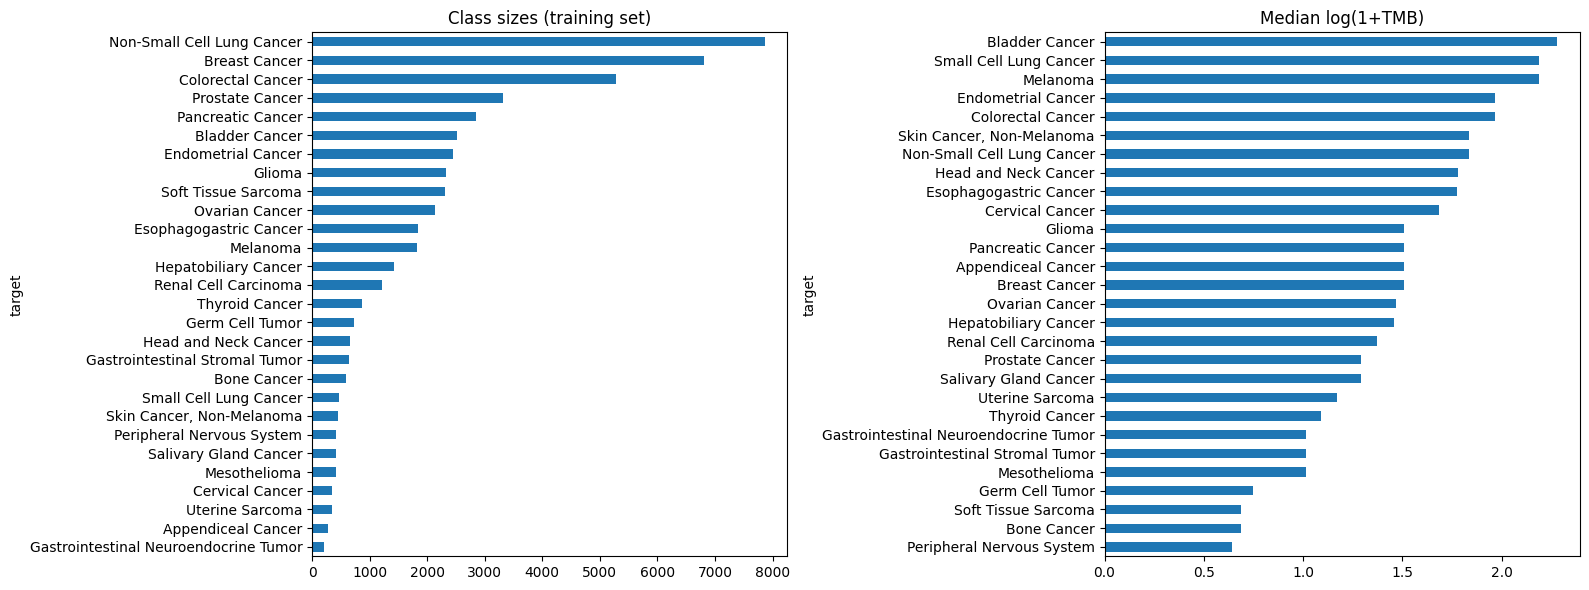

In [76]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
lab.target.value_counts().sort_values().plot.barh(ax=ax[0]); ax[0].set_title("Class sizes (training set)")
lab.groupby('target')['log_tmb'].median().sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Median log(1+TMB)")
plt.tight_layout(); plt.show()

In [77]:
MUT_PATH = None   # e.g. "data_mutations.txt" after uploading it with files.upload()
N_GENES = 150
GENE_COLS = []

if MUT_PATH:
    mut = pd.read_csv(MUT_PATH, sep='\t', comment='#', low_memory=False,
                      usecols=['Hugo_Symbol','Tumor_Sample_Barcode','Variant_Classification'])
    silent = {'Silent','Intron',"3'UTR","5'UTR","3'Flank","5'Flank",'IGR','RNA'}
    mut = mut[~mut.Variant_Classification.isin(silent)]
    top_genes = mut.groupby('Hugo_Symbol').Tumor_Sample_Barcode.nunique().nlargest(N_GENES).index
    mut = mut[mut.Hugo_Symbol.isin(top_genes)].drop_duplicates(['Tumor_Sample_Barcode','Hugo_Symbol'])
    G = pd.crosstab(mut.Tumor_Sample_Barcode, mut.Hugo_Symbol).clip(upper=1)
    G.columns = ['mut_' + g for g in G.columns]
    GENE_COLS = list(G.columns)
    for frame_name in ['lab', 'cup_df']:
        fr = globals()[frame_name]
        g = G.reindex(fr['sample_id']).fillna(0).reset_index(drop=True)
        globals()[frame_name] = pd.concat([fr.reset_index(drop=True), g], axis=1)
    print("Added", len(GENE_COLS), "gene features")

In [78]:
le = LabelEncoder().fit(lab.target)
y_all = le.transform(lab.target)
CLASSES = list(le.classes_); N_CLS = len(CLASSES)

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_idx, tmp_idx = next(gss.split(lab, groups=lab.patient_id))
tmp = lab.iloc[tmp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
va_rel, te_rel = next(gss2.split(tmp, groups=tmp.patient_id))
va_idx, te_idx = tmp_idx[va_rel], tmp_idx[te_rel]

transformers = [
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                      ('sc', StandardScaler())]), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)]
if GENE_COLS:
    transformers.append(('gene', 'passthrough', GENE_COLS))
pre = ColumnTransformer(transformers)

X_tr = pre.fit_transform(lab.iloc[tr_idx]).astype(np.float32)
X_va = pre.transform(lab.iloc[va_idx]).astype(np.float32)
X_te = pre.transform(lab.iloc[te_idx]).astype(np.float32)
y_tr, y_va, y_te = y_all[tr_idx], y_all[va_idx], y_all[te_idx]
print(X_tr.shape, X_va.shape, X_te.shape)

(35648, 76) (7684, 76) (7643, 76)


ep   0 | train 3.440 | val 2.969 | val acc 0.260
ep   5 | train 2.836 | val 2.214 | val acc 0.406
ep  10 | train 2.681 | val 2.062 | val acc 0.438
ep  15 | train 2.591 | val 1.966 | val acc 0.452
ep  20 | train 2.534 | val 1.940 | val acc 0.459
ep  25 | train 2.493 | val 1.908 | val acc 0.466
ep  30 | train 2.454 | val 1.899 | val acc 0.466
ep  35 | train 2.421 | val 1.897 | val acc 0.467
ep  40 | train 2.382 | val 1.874 | val acc 0.466
ep  45 | train 2.349 | val 1.870 | val acc 0.470
ep  50 | train 2.316 | val 1.898 | val acc 0.464
ep  55 | train 2.286 | val 1.879 | val acc 0.467
ep  60 | train 2.260 | val 1.886 | val acc 0.471
Early stop at epoch 60


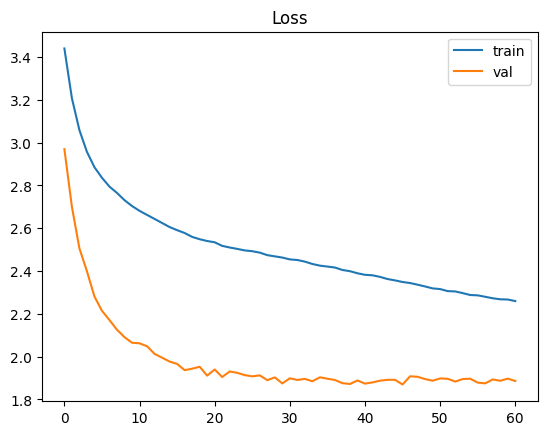

In [79]:
class Net(nn.Module):
    def __init__(self, d_in, n_cls, h=512, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, h), nn.BatchNorm1d(h), nn.GELU(), nn.Dropout(p),
            nn.Linear(h, h//2), nn.BatchNorm1d(h//2), nn.GELU(), nn.Dropout(p),
            nn.Linear(h//2, h//4), nn.BatchNorm1d(h//4), nn.GELU(), nn.Dropout(p/2),
            nn.Linear(h//4, n_cls))
    def forward(self, x): return self.net(x)

model = Net(X_tr.shape[1], N_CLS).to(DEVICE)

# soften class imbalance with sqrt inverse-frequency weights
counts = np.bincount(y_tr, minlength=N_CLS)
w = (counts.sum() / (N_CLS * counts)) ** 0.5
w = torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)

mk = lambda X, y, shuf: DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long()),
                                   batch_size=256, shuffle=shuf)
dl_tr, dl_va = mk(X_tr, y_tr, True), mk(X_va, y_va, False)

EPOCHS, PATIENCE = 150, 15
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, epochs=EPOCHS, steps_per_epoch=len(dl_tr))

best, best_state, bad = 1e9, None, 0
hist = {'tr':[], 'va':[], 'va_acc':[]}
for ep in range(EPOCHS):
    model.train(); tl = 0
    for xb, yb in dl_tr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        loss = F.cross_entropy(model(xb), yb, weight=w, label_smoothing=0.1)
        loss.backward(); opt.step(); sched.step(); tl += loss.item() * len(xb)
    model.eval(); vl, corr = 0, 0
    with torch.no_grad():
        for xb, yb in dl_va:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb); vl += F.cross_entropy(out, yb).item() * len(xb)
            corr += (out.argmax(1) == yb).sum().item()
    hist['tr'].append(tl/len(X_tr)); hist['va'].append(vl/len(X_va)); hist['va_acc'].append(corr/len(X_va))
    if hist['va'][-1] < best - 1e-4:
        best, bad = hist['va'][-1], 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
    if ep % 5 == 0: print(f"ep {ep:3d} | train {hist['tr'][-1]:.3f} | val {hist['va'][-1]:.3f} | val acc {hist['va_acc'][-1]:.3f}")
    if bad >= PATIENCE: print("Early stop at epoch", ep); break

model.load_state_dict(best_state)
plt.plot(hist['tr'], label='train'); plt.plot(hist['va'], label='val'); plt.legend(); plt.title("Loss"); plt.show()

Temperature: 0.835
Top-1: 0.454 | Top-3: 0.705 | Macro-F1: 0.346
Top-1 on metastatic samples only (closest to CUP): 0.458
                                       precision    recall  f1-score   support

                   Appendiceal Cancer       0.08      0.09      0.09        32
                       Bladder Cancer       0.52      0.52      0.52       359
                          Bone Cancer       0.30      0.36      0.33       110
                        Breast Cancer       0.55      0.67      0.61      1017
                      Cervical Cancer       0.06      0.06      0.06        47
                    Colorectal Cancer       0.51      0.44      0.47       775
                   Endometrial Cancer       0.41      0.54      0.47       364
               Esophagogastric Cancer       0.22      0.16      0.19       269
Gastrointestinal Neuroendocrine Tumor       0.15      0.21      0.18        38
       Gastrointestinal Stromal Tumor       0.29      0.46      0.36       103
        

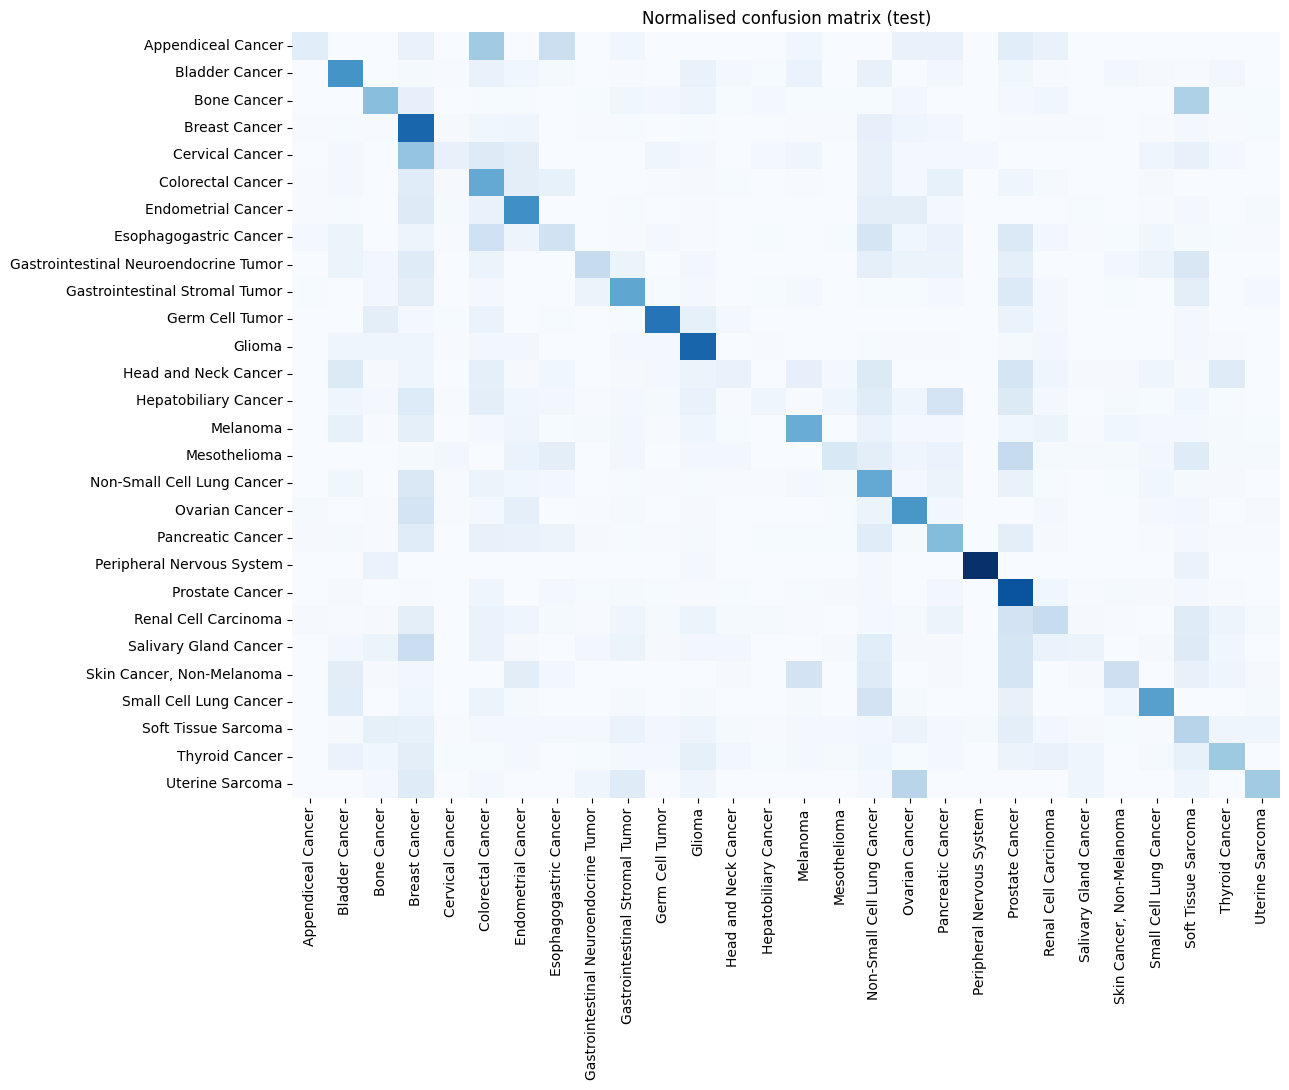

conf >= 0.3: 77.2% of samples, accuracy 0.518
conf >= 0.5: 40.5% of samples, accuracy 0.643
conf >= 0.7: 18.5% of samples, accuracy 0.778
conf >= 0.9: 4.5% of samples, accuracy 0.913


In [80]:
@torch.no_grad()
def logits_of(X):
    model.eval()
    return model(torch.from_numpy(X).to(DEVICE)).cpu()

# temperature scaling on validation set so probabilities are honest
T = torch.nn.Parameter(torch.ones(1))
lbfgs = torch.optim.LBFGS([T], lr=0.1, max_iter=100)
lv, yv = logits_of(X_va), torch.from_numpy(y_va).long()
def closure():
    lbfgs.zero_grad(); l = F.cross_entropy(lv / T, yv); l.backward(); return l
lbfgs.step(closure); TEMP = float(T.item()); print("Temperature:", round(TEMP, 3))

proba = F.softmax(logits_of(X_te) / TEMP, 1).numpy()
pred = proba.argmax(1)
top3 = np.mean([y_te[i] in np.argsort(-proba[i])[:3] for i in range(len(y_te))])
print(f"Top-1: {(pred==y_te).mean():.3f} | Top-3: {top3:.3f} | Macro-F1: {f1_score(y_te, pred, average='macro'):.3f}")

met = (lab.iloc[te_idx]['disease_status'] == 'Metastasis').values
print(f"Top-1 on metastatic samples only (closest to CUP): {(pred[met]==y_te[met]).mean():.3f}")

print(classification_report(y_te, pred, target_names=CLASSES, zero_division=0))
cm = confusion_matrix(y_te, pred, normalize='true')
plt.figure(figsize=(13, 11)); sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap='Blues', cbar=False)
plt.title("Normalised confusion matrix (test)"); plt.tight_layout(); plt.show()

# does confidence mean anything? accuracy vs confidence
conf = proba.max(1)
for t in [0.3, 0.5, 0.7, 0.9]:
    m = conf >= t
    print(f"conf >= {t}: {m.mean():.1%} of samples, accuracy {(pred[m]==y_te[m]).mean():.3f}" if m.any() else f"conf >= {t}: none")

,sample_id,patient_id,age,sex,met_site,pred1,prob1,pred2,prob2,pred3,prob3
0,P-0000273-T01-IM3,P-0000273,41.0,Female,Other,Breast Cancer,0.564,Ovarian Cancer,0.092,Uterine Sarcoma,0.074
1,P-0000277-T01-IM3,P-0000277,43.0,Female,Lymph Node,Salivary Gland Cancer,0.270,Thyroid Cancer,0.211,"Skin Cancer, Non-Melanoma",0.083
2,P-0000324-T01-IM3,P-0000324,67.0,Female,Liver,Breast Cancer,0.285,Pancreatic Cancer,0.198,Hepatobiliary Cancer,0.065
3,P-0000326-T01-IM3,P-0000326,66.0,Male,Liver,Thyroid Cancer,0.342,Bladder Cancer,0.291,Pancreatic Cancer,0.093
4,P-0000336-T01-IM3,P-0000336,69.0,Male,Lymph Node,Bladder Cancer,0.329,"Skin Cancer, Non-Melanoma",0.292,Non-Small Cell Lung Cancer,0.153
5,P-0000357-T01-IM3,P-0000357,48.0,Female,Liver,Breast Cancer,0.520,Gastrointestinal Neuroendocrine Tumor,0.106,Uterine Sarcoma,0.080
6,P-0000515-T01-IM3,P-0000515,54.0,Female,Other,Breast Cancer,0.499,Ovarian Cancer,0.095,Non-Small Cell Lung Cancer,0.093
7,P-0000536-T01-IM3,P-0000536,76.0,Male,Lymph Node,Prostate Cancer,0.497,Salivary Gland Cancer,0.112,"Skin Cancer, Non-Melanoma",0.106
8,P-0000591-T01-IM3,P-0000591,75.0,Male,Other,"Skin Cancer, Non-Melanoma",0.410,Non-Small Cell Lung Cancer,0.138,Bladder Cancer,0.075
9,P-0000709-T01-IM3,P-0000709,45.0,Female,Ovary,Breast Cancer,0.582,Esophagogastric Cancer,0.081,Colorectal Cancer,0.057


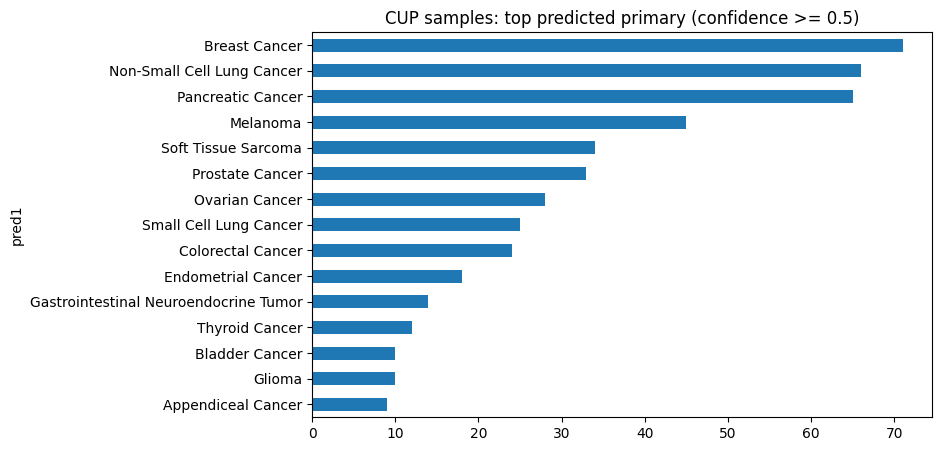

In [81]:
X_cup = pre.transform(cup_df).astype(np.float32)
p_cup = F.softmax(logits_of(X_cup) / TEMP, 1).numpy()
order = np.argsort(-p_cup, axis=1)[:, :3]

cup_out = cup_df[['sample_id','patient_id','age','sex','met_site']].copy().reset_index(drop=True)
for k in range(3):
    cup_out[f'pred{k+1}'] = [CLASSES[i] for i in order[:, k]]
    cup_out[f'prob{k+1}'] = np.take_along_axis(p_cup, order[:, [k]], 1).ravel().round(3)
cup_out.to_csv("cup_predictions.csv", index=False)
display(cup_out.head(10))

cup_out[cup_out.prob1 >= 0.5].pred1.value_counts().head(15).sort_values().plot.barh(figsize=(8,5))
plt.title("CUP samples: top predicted primary (confidence >= 0.5)"); plt.show()

In [82]:
torch.save({'state': model.state_dict(), 'd_in': X_tr.shape[1], 'n_cls': N_CLS}, "cup_model.pt")
joblib.dump(pre, "preprocessor.joblib")
json.dump({'classes': CLASSES, 'temp': TEMP, 'met_top': MET_TOP, 'gene_cols': GENE_COLS}, open("meta.json", "w"))

In [83]:
import gradio as gr

def predict_frame(d):
    d = clean_clinical(d) if 'age' not in d.columns else d
    for c in GENE_COLS:
        if c not in d.columns: d[c] = 0
    X = pre.transform(d).astype(np.float32)
    return F.softmax(logits_of(X) / TEMP, 1).numpy()

def single(age, sex, ancestry, disease_status, sample_type, panel, met_site, msi_type,
           msi_score, tmb, mut_count, fga, ploidy, purity, wgd, n_other, genes):
    row = dict(age=age, sex=sex, ancestry=ancestry, disease_status=disease_status, sample_type=sample_type,
               panel=panel, met_site=met_site, msi_type=msi_type, msi_score=msi_score,
               log_tmb=np.log1p(max(tmb, 0)), log_mut_count=np.log1p(max(mut_count, 0)),
               fga=fga, ploidy=ploidy, facets_purity=purity, wgd=float(wgd), n_other_cancers=n_other,
               n_samples=1, coverage=float(lab.coverage.median()), path_purity=np.nan,
               facets_pass=1.0, purity_from_mut=0.0, somatic_status='Matched')
    d = pd.DataFrame([row])
    mutated = {g.strip().upper() for g in (genes or "").split(",") if g.strip()}
    for c in GENE_COLS: d[c] = float(c.replace('mut_', '') in mutated)
    p = predict_frame(d)[0]
    top = np.argsort(-p)[:5]
    note = "Low confidence: treat as hypothesis only." if p[top[0]] < 0.4 else "Moderate/high model confidence."
    return {CLASSES[i]: float(p[i]) for i in top}, note

def batch(file):
    d = pd.read_csv(file.name, sep=None, engine='python')
    d = clean_clinical(d)
    p = predict_frame(d)
    o = np.argsort(-p, 1)[:, :3]
    out = pd.DataFrame({'sample_id': d.get('sample_id', range(len(d)))})
    for k in range(3):
        out[f'pred{k+1}'] = [CLASSES[i] for i in o[:, k]]
        out[f'prob{k+1}'] = np.take_along_axis(p, o[:, [k]], 1).ravel().round(3)
    out.to_csv("batch_predictions.csv", index=False)
    return out, "batch_predictions.csv"

opts = lambda c: sorted(lab[c].unique().tolist())
with gr.Blocks(title="CUP Primary Site Predictor") as demo:
    gr.Markdown("# CUP primary-site predictor (clinical + NGS summary features)\nResearch prototype only, not for clinical decisions.")
    with gr.Tab("Single sample"):
        with gr.Row():
            with gr.Column():
                age = gr.Number(label="Age at diagnosis", value=60)
                sex = gr.Dropdown(opts('sex'), value='Female', label="Sex")
                ancestry = gr.Dropdown(opts('ancestry'), value='nonASJ-EUR', label="Genetic ancestry")
                ds = gr.Dropdown(opts('disease_status'), value='Metastasis', label="Disease status")
                st = gr.Dropdown(opts('sample_type'), value='Metastasis', label="Sample type")
                panel = gr.Dropdown(opts('panel'), value='IMPACT468', label="Gene panel")
                ms = gr.Dropdown(sorted(MET_TOP + ['Other']), value='Liver', label="Metastatic site")
            with gr.Column():
                msit = gr.Dropdown(opts('msi_type'), value='Stable', label="MSI type")
                msis = gr.Number(label="MSI score", value=1.0)
                tmb = gr.Number(label="TMB (mut/Mb)", value=5.0)
                mc = gr.Number(label="Mutation count", value=6)
                fga = gr.Slider(0, 1, value=0.2, label="Fraction genome altered")
                ploidy = gr.Number(label="Ploidy (FACETS)", value=2.2)
                pur = gr.Slider(0, 1, value=0.5, label="FACETS purity")
                wgd = gr.Checkbox(label="Whole genome doubling")
                noc = gr.Number(label="Number of other cancer types", value=0, precision=0)
                genes = gr.Textbox(label="Mutated genes, comma-separated (used only if Cell 5 was enabled)", placeholder="TP53, KRAS, ...")
        btn = gr.Button("Predict", variant="primary")
        lbl = gr.Label(num_top_classes=5, label="Predicted primary site")
        msg = gr.Markdown()
        btn.click(single, [age, sex, ancestry, ds, st, panel, ms, msit, msis, tmb, mc, fga, ploidy, pur, wgd, noc, genes], [lbl, msg])
    with gr.Tab("Batch (TSV/CSV)"):
        gr.Markdown("Upload a file with the same columns as the original MSK-IMPACT clinical TSV.")
        f = gr.File(label="Upload")
        tbl = gr.Dataframe(); dl = gr.File(label="Download predictions")
        gr.Button("Run").click(batch, f, [tbl, dl])

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7255e98c4f4312bac9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
